In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
data = {"Position": ["Striker", "Forward", "Attacking Midfielder", "Winger"],"Injured": [45, 56, 24, 20],"Not Injured": [32, 38, 11, 9]}
df = pd.DataFrame(data)
df

,Position,Injured,Not Injured
0,Striker,45,32
1,Forward,56,38
2,Attacking Midfielder,24,11
3,Winger,20,9


In [4]:
df["Total"] = df["Injured"] + df["Not Injured"]
df

,Position,Injured,Not Injured,Total
0,Striker,45,32,77
1,Forward,56,38,94
2,Attacking Midfielder,24,11,35
3,Winger,20,9,29


In [7]:
total_injured = df["Injured"].sum()
total_not_injured = df["Not Injured"].sum()
total_players = df["Total"].sum()
print("Total injured:", total_injured)
print("Total not injured:", total_not_injured)
print("Total players:", total_players)

Total injured: 145
Total not injured: 90
Total players: 235


In [8]:
probability_injury = total_injured / total_players
print("Probability of injury:", round(probability_injury, 4))

Probability of injury: 0.617


## probability that a randomly chosen player would suffer with injury is 0.617, meaning there is approximately a 61.7% chance of injury among the players in the given data.

In [11]:
forward_players = 94
winger_players = 29
probability_forward_or_winger = (forward_players + winger_players) / total_players
print("Probability of forward or winger:", round(probability_forward_or_winger, 4))

Probability of forward or winger: 0.5234


## the probability that a randomly chosen player is a forward or a winger is 0.5234, or approximately 52.34%.

In [13]:
striker_injured = 45
probability_striker_injured = striker_injured / total_players
print("Probability of striker and injury:", round(probability_striker_injured, 4))

Probability of striker and injury: 0.1915


## the probability that a randomly chosen player is a striker and has a foot injury is 0.1915, or approximately 19.15%.

In [14]:
injured_strikers = 45
total_injured = 145
probability_striker_given_injury = injured_strikers / total_injured
print("Probability of striker given injury:",round(probability_striker_given_injury, 4))

Probability of striker given injury: 0.3103


## Therefore, the probability that a randomly chosen injured player is a striker is 0.3103, or approximately 31.03%.

In [16]:
df = pd.read_csv("/content/Bags.csv")

In [17]:
df.head()

,Machine 1,Machine 2
0,2.95,3.22
1,3.45,3.30
2,3.50,3.34
3,3.75,3.28
4,3.48,3.29


In [18]:
print(df.shape)

(26, 2)


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Machine 1  25 non-null     float64
 1   Machine 2  22 non-null     float64
dtypes: float64(2)
memory usage: 548.0 bytes


In [20]:
from scipy.stats import norm

In [28]:
mu = 5
sigma = 1.5
x = 3.17
z = (x - mu) / sigma
proportion = norm.cdf(z)
print("Z-score:", z)
print("Proportion:", proportion)

Z-score: -1.22
Proportion: 0.11123243744783456


## Approximately 11.12% of the gunny bags have a breaking strength of less than 3.17 kg per sq cm.

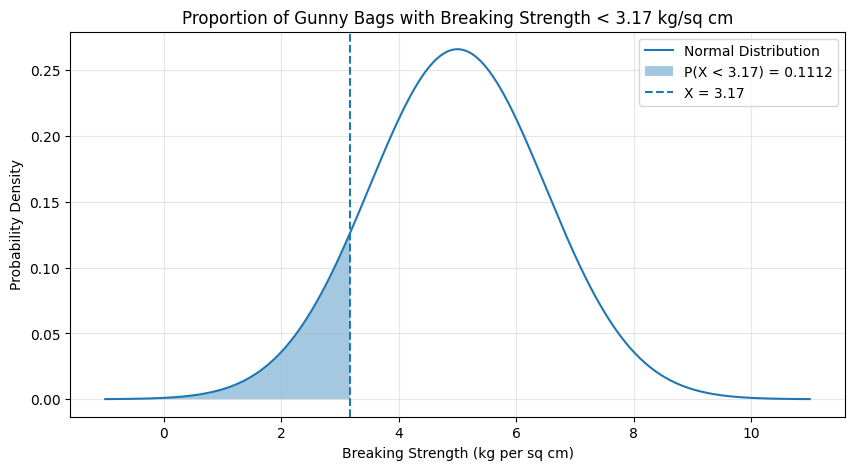

In [30]:
x_values = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y_values = norm.pdf(x_values, mu, sigma)
plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label='Normal Distribution')
x_shaded = np.linspace(mu - 4*sigma, x, 500)
y_shaded = norm.pdf(x_shaded, mu, sigma)
plt.fill_between(x_shaded, y_shaded, alpha=0.4,label='P(X < 3.17) = 0.1112')
plt.axvline(x, linestyle='--', label='X = 3.17')
plt.xlabel('Breaking Strength (kg per sq cm)')
plt.ylabel('Probability Density')
plt.title('Proportion of Gunny Bags with Breaking Strength < 3.17 kg/sq cm')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [37]:
mu = 5
sigma = 1.5
x = 3.6
z = (x - mu) / sigma
proportion = 1 - norm.cdf(z)
print("Z-score:", z)
print("Proportion:", proportion)


Z-score: -0.9333333333333332
Proportion: 0.8246760551477705


## the proportion of gunny bags having a breaking strength of at least 3.6 kg per sq cm is approximately 0.8247.

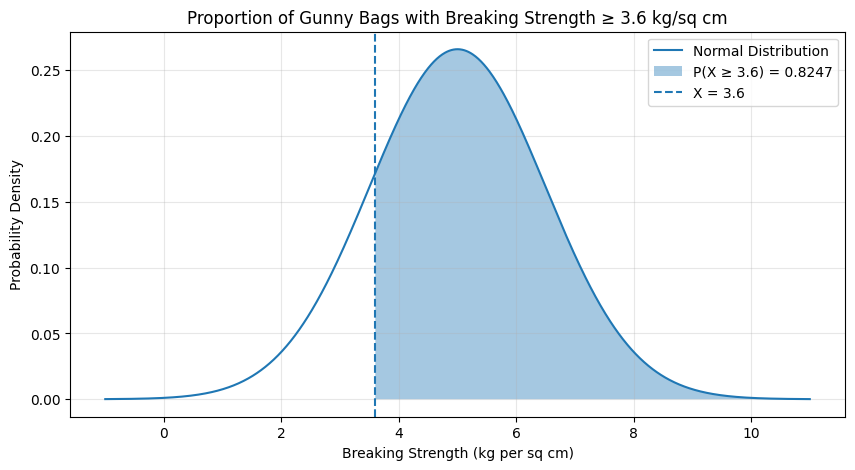

In [36]:
x_values = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y_values = norm.pdf(x_values, mu, sigma)
plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label='Normal Distribution')
x_shaded = np.linspace(x, mu + 4*sigma, 500)
y_shaded = norm.pdf(x_shaded, mu, sigma)
plt.fill_between(x_shaded,y_shaded,alpha=0.4,label='P(X ≥ 3.6) = 0.8247')
plt.axvline(x,linestyle='--',label='X = 3.6')
plt.xlabel('Breaking Strength (kg per sq cm)')
plt.ylabel('Probability Density')
plt.title('Proportion of Gunny Bags with Breaking Strength ≥ 3.6 kg/sq cm')
plt.legend()
plt.grid(alpha=0.3)
plt.show()



In [38]:
mu = 5
sigma = 1.5
lower = 5
upper = 5.5
z_lower = (lower - mu) / sigma
z_upper = (upper - mu) / sigma
proportion = norm.cdf(z_upper) - norm.cdf(z_lower)
print("Lower Z-score:", z_lower)
print("Upper Z-score:", z_upper)
print("Proportion:", proportion)

Lower Z-score: 0.0
Upper Z-score: 0.3333333333333333
Proportion: 0.13055865981823633


## Therefore, approximately 0.1306 of the gunny bags have a breaking strength between 5 and 5.5 kg per sq cm.

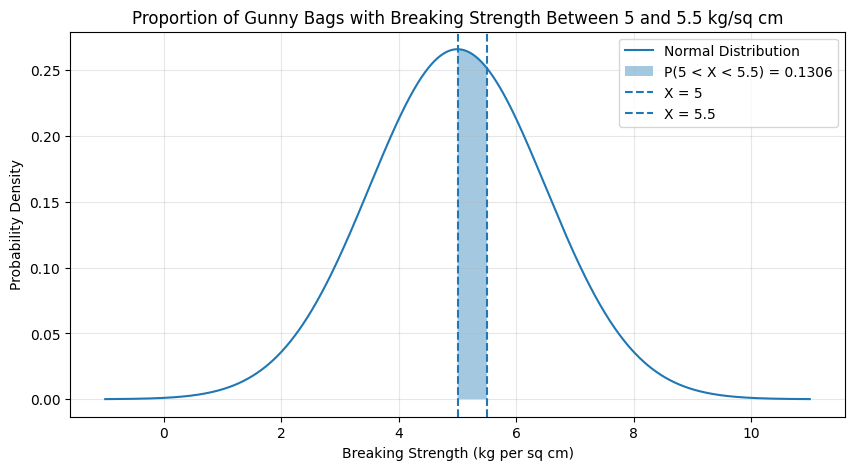

In [39]:
x_values = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y_values = norm.pdf(x_values, mu, sigma)
plt.figure(figsize=(10, 5))
plt.plot(x_values, y_values, label='Normal Distribution')
x_shaded = np.linspace(lower, upper, 300)
y_shaded = norm.pdf(x_shaded, mu, sigma)
plt.fill_between(x_shaded,y_shaded,alpha=0.4,label='P(5 < X < 5.5) = 0.1306')
plt.axvline(lower, linestyle='--', label='X = 5')
plt.axvline(upper, linestyle='--', label='X = 5.5')
plt.xlabel('Breaking Strength (kg per sq cm)')
plt.ylabel('Probability Density')
plt.title('Proportion of Gunny Bags with Breaking Strength Between 5 and 5.5 kg/sq cm')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:
mu = 5
sigma = 1.5
lower = 3
upper = 7.5
z_lower = (lower - mu) / sigma
z_upper = (upper - mu) / sigma
proportion = norm.cdf(z_lower) + (1 - norm.cdf(z_upper))
print("Z-score for 3:", z_lower)
print("Z-score for 7.5:", z_upper)

Z-score for 3: -1.3333333333333333
Z-score for 7.5: 1.6666666666666667


## Approximately 0.1393, or 13.93% of the gunny bags have a breaking strength NOT between 3 and 7.5 kg/cm².

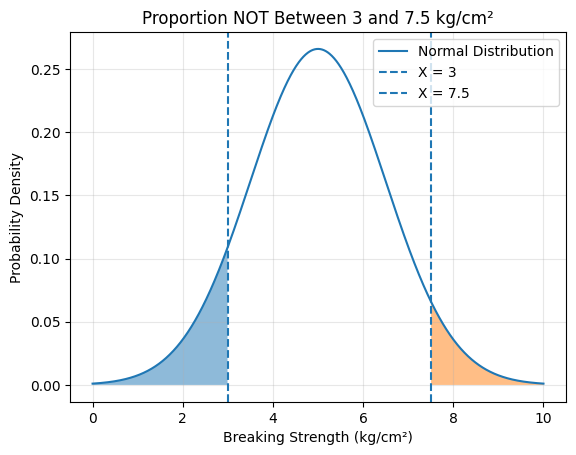

In [44]:
x = np.linspace(0, 10, 1000)
y = norm.pdf(x, mu, sigma)
plt.plot(x, y, label="Normal Distribution")
x_left = x[x < 3]
plt.fill_between(x_left, norm.pdf(x_left, mu, sigma), alpha=0.5)
x_right = x[x > 7.5]
plt.fill_between(x_right, norm.pdf(x_right, mu, sigma), alpha=0.5)
plt.axvline(3, linestyle="--", label="X = 3")
plt.axvline(7.5, linestyle="--", label="X = 7.5")
plt.xlabel("Breaking Strength (kg/cm²)")
plt.ylabel("Probability Density")
plt.title("Proportion NOT Between 3 and 7.5 kg/cm²")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [46]:
Zing = pd.read_csv("/content/Zingaro_Company (1).csv")

In [52]:
Zing.columns = Zing.columns.str.strip()
t_stat, p_value = stats.ttest_1samp(Zing['Unpolished'], popmean=150, alternative='less')
t_crit = stats.t.ppf(0.05, df=len(Zing) - 1)
print("t-statistic:", t_stat)
print("critical value:", t_crit)
print("p-value:", p_value)

t-statistic: -4.164629601426757
critical value: -1.6657068927340237
p-value: 4.171286997419652e-05


## At the 5% significance level, the t-statistic (−4.165) falls below the critical value (−1.666) and the p-value (≈ 0.00004) is less than 0.05, so we reject H₀. The mean hardness of unpolished stones (134.11) is significantly below 150, so Zingaro is justified in believing they are unsuitable for optimum printing.

In [57]:
dental = pd.read_excel("/content/Dental Hardness data.xlsx")


In [66]:
dental['Dentist'].unique()


array([1, 2, 3, 4, 5])

In [70]:
dental.head()

,Dentist,Method,Alloy,Temp,Response
0,1,1,1,1500,813
1,1,1,1,1600,792
2,1,1,1,1700,792
3,1,1,2,1500,907
4,1,1,2,1600,792


Dentist
1    783.055556
2    786.666667
3    748.611111
4    713.666667
5    676.888889
Name: Response, dtype: float64


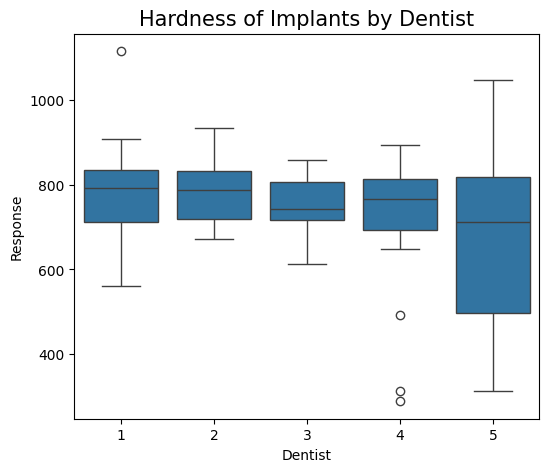

In [98]:
print(dental.groupby('Dentist')['Response'].mean())

fig, ax = plt.subplots(figsize=(6, 5))
a = sns.boxplot(x='Dentist', y='Response', data=dental)
a.set_title("Hardness of Implants by Dentist", fontsize=15)
ax.set_xlabel('Dentist')
ax.set_ylabel('Response')
plt.show()

In [99]:
w, p_value = stats.shapiro(dental["Response"])
print("the p value is", p_value)

the p value is 8.079982979541578e-06


In [110]:
statistic, p_value = levene(
    dental[dental['Dentist'] == 1]['Response'],
    dental[dental['Dentist'] == 2]['Response'],
    dental[dental['Dentist'] == 3]['Response']
)

print('The p-value is', p_value)

The p-value is 0.21132044225803936


In [116]:
from scipy.stats import f_oneway
test_stat, p_value = f_oneway(
    dental.loc[dental["Dentist"] == 1, "Response"],
    dental.loc[dental["Dentist"] == 2, "Response"]
)
print("The p-value is", p_value)

The p-value is 0.9196191845792405


In [119]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

m_comp = pairwise_tukeyhsd(
    endog=dental["Response"],
    groups=dental["Dentist"],
    alpha=0.05
)

print(m_comp)

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower    upper   reject
--------------------------------------------------------
     1      2    3.6111    1.0 -129.0594 136.2816  False
     1      3  -34.4444 0.9505 -167.1149   98.226  False
     1      4  -69.3889 0.5925 -202.0594  63.2816  False
     1      5 -106.1667 0.1786 -238.8371  26.5038  False
     2      3  -38.0556 0.9301  -170.726  94.6149  False
     2      4     -73.0 0.5438 -205.6705  59.6705  False
     2      5 -109.7778  0.153 -242.4483  22.8927  False
     3      4  -34.9444 0.9479 -167.6149   97.726  False
     3      5  -71.7222  0.561 -204.3927  60.9483  False
     4      5  -36.7778 0.9378 -169.4483  95.8927  False
--------------------------------------------------------


## Tukey's HSD test shows that there is no statistically significant difference in mean implant hardness between any pair of dentists at the 5% significance level.

Method
1    793.900000
2    804.333333
3    627.100000
Name: Response, dtype: float64


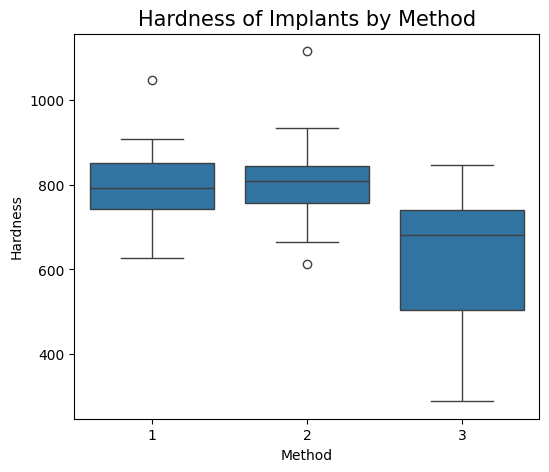

In [121]:
print(dental.groupby('Method')['Response'].mean())

fig, ax = plt.subplots(figsize=(6, 5))
a = sns.boxplot(x='Method', y='Response', data=dental)
a.set_title("Hardness of Implants by Method", fontsize=15)
ax.set_xlabel("Method")
ax.set_ylabel("Hardness")

plt.show()

In [122]:
from scipy.stats import f_oneway
groups = [group['Response'].values
          for name, group in dental.groupby('Method')]
test_stat, p_value = f_oneway(*groups)
print("The p-value is", p_value)

The p-value is 7.683891892977938e-08


In [125]:
dental.head()

,Dentist,Method,Alloy,Temp,Response
0,1,1,1,1500,813
1,1,1,1,1600,792
2,1,1,1,1700,792
3,1,1,2,1500,907
4,1,1,2,1600,792


In [124]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
m_comp = pairwise_tukeyhsd(
    endog=dental["Response"],
    groups=dental["Method"],
    alpha=0.05
)
print(m_comp)

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower     upper   reject
---------------------------------------------------------
     1      2   10.4333 0.9415  -64.7584   85.6251  False
     1      3    -166.8    0.0 -241.9917  -91.6083   True
     2      3 -177.2333    0.0 -252.4251 -102.0416   True
---------------------------------------------------------


## The hardness of implants varies depending on the method. Method 3 has significantly different mean hardness compared with Methods 1 and 2, while Methods 1 and 2 have similar mean hardness.

In [129]:
print(dental.groupby('Dentist')['Response'].agg(['mean', 'var', 'std']).round(1))
print(dental.groupby('Method')['Response'].agg(['mean', 'var', 'std']).round(1))
print(dental.groupby(['Alloy', 'Dentist', 'Method'])['Response'].agg(['mean', 'var']).round(1))

          mean      var    std
Dentist                       
1        783.1  16713.7  129.3
2        786.7   5995.6   77.4
3        748.6   4861.7   69.7
4        713.7  31758.5  178.2
5        676.9  42629.4  206.5
         mean      var    std
Method                       
1       793.9   7477.5   86.5
2       804.3   9172.1   95.8
3       627.1  28097.5  167.6
                       mean      var
Alloy Dentist Method                
1     1       1       799.0    147.0
              2       715.0   3639.0
              3       735.7  11756.3
      2       1       777.0   2908.0
              2       765.7    410.3
              3       741.0   7068.0
      3       1       707.3   4860.3
              2       723.0  10300.0
              3       722.3   1281.3
      4       1       765.7    610.3
              2       781.3   9281.3
              3       496.3  43689.3
      5       1       706.7     72.3
              2       740.0   4869.0
              3       436.3   1697.3
2   

In [130]:
for al in [1, 2]:
    sub = dental[dental.Alloy == al]
    model = ols('Response ~ C(Dentist) * C(Method)', data=sub).fit()
    print(f'\n===== Alloy {al} =====')
    print(sm.stats.anova_lm(model, typ=2).round(4))


===== Alloy 1 =====
                           sum_sq    df        F  PR(>F)
C(Dentist)            106683.6889   4.0   3.8996  0.0115
C(Method)             148472.1778   2.0  10.8543  0.0003
C(Dentist):C(Method)  185941.3778   8.0   3.3984  0.0068
Residual              205180.0000  30.0      NaN     NaN

===== Alloy 2 =====
                           sum_sq    df        F  PR(>F)
C(Dentist)             56797.9111   4.0   1.1062  0.3718
C(Method)             499640.4000   2.0  19.4612  0.0000
C(Dentist):C(Method)  197459.8222   8.0   1.9228  0.0932
Residual              385104.6667  30.0      NaN     NaN


Alloy 1: p = 0.0068 is below 0.05, so we reject H0. The interaction is significant.
## Alloy 2: p = 0.0932 is above 0.05, so we fail to reject H0. The interaction is not significant at 5%.

In [131]:
model_all = ols('Response ~ C(Dentist) * C(Method)', data=dental).fit()
print(sm.stats.anova_lm(model_all, typ=2).round(4))

                           sum_sq    df        F  PR(>F)
C(Dentist)            157794.5556   4.0   3.5501  0.0105
C(Method)             593427.4889   2.0  26.7020  0.0000
C(Dentist):C(Method)  306471.8444   8.0   3.4475  0.0020
Residual              833401.6667  75.0      NaN     NaN


In [132]:
print(pairwise_tukeyhsd(dental['Response'], dental['Dentist']))
print(pairwise_tukeyhsd(dental['Response'], dental['Method']))
dental['DM'] = dental['Dentist'].astype(str) + '-' + dental['Method'].astype(str)
for al in [1, 2]:
    s = dental[dental.Alloy == al]
    t = pairwise_tukeyhsd(s['Response'], s['DM'])
    res = pd.DataFrame(t._results_table.data[1:], columns=t._results_table.data[0])
    print(f'\nAlloy {al}: significant pairs')
    print(res[res['reject'] == True])

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower    upper   reject
--------------------------------------------------------
     1      2    3.6111    1.0 -129.0594 136.2816  False
     1      3  -34.4444 0.9505 -167.1149   98.226  False
     1      4  -69.3889 0.5925 -202.0594  63.2816  False
     1      5 -106.1667 0.1786 -238.8371  26.5038  False
     2      3  -38.0556 0.9301  -170.726  94.6149  False
     2      4     -73.0 0.5438 -205.6705  59.6705  False
     2      5 -109.7778  0.153 -242.4483  22.8927  False
     3      4  -34.9444 0.9479 -167.6149   97.726  False
     3      5  -71.7222  0.561 -204.3927  60.9483  False
     4      5  -36.7778 0.9378 -169.4483  95.8927  False
--------------------------------------------------------
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower     upper   reject
---------------------------------------------------------
     1      2   10.4333 0.94

### The two-way ANOVA (F-test) shows that the interaction depends on the alloy. For Alloy 1, the Dentist × Method interaction is significant (F = 3.40, p = 0.007), which means the effect of a method on hardness changes from dentist to dentist. For Alloy 2, the interaction is not significant at the 5% level (p = 0.093), although the same pattern is visible. Levene's test showed equal variances for both alloys (p = 0.313 and 0.783), so these ANOVA results are reliable.

In [133]:

for al in [1, 2]:
    s = dental[dental.Alloy == al]
    groups = [g['Response'].values for _, g in s.groupby('DM')]
    print(f'Alloy {al}:', stats.levene(*groups, center='median'))
print('Dentist:', stats.levene(*[g['Response'].values for _, g in dental.groupby('Dentist')]))
print('Method:', stats.levene(*[g['Response'].values for _, g in dental.groupby('Method')]))
print('Dentist x Method:', stats.levene(*[g['Response'].values for _, g in dental.groupby('DM')]))

Alloy 1: LeveneResult(statistic=np.float64(1.2188532077858198), pvalue=np.float64(0.3128166652989495))
Alloy 2: LeveneResult(statistic=np.float64(0.6709660298340363), pvalue=np.float64(0.7831735515657826))
Dentist: LeveneResult(statistic=np.float64(3.7082282441933954), pvalue=np.float64(0.007858817382355401))
Method: LeveneResult(statistic=np.float64(5.848571977210466), pvalue=np.float64(0.004138452940152019))
Dentist x Method: LeveneResult(statistic=np.float64(2.617903099218198), pvalue=np.float64(0.003863706288294136))


Dentist
1    783.055556
2    786.666667
3    748.611111
4    713.666667
5    676.888889
Name: Response, dtype: float64


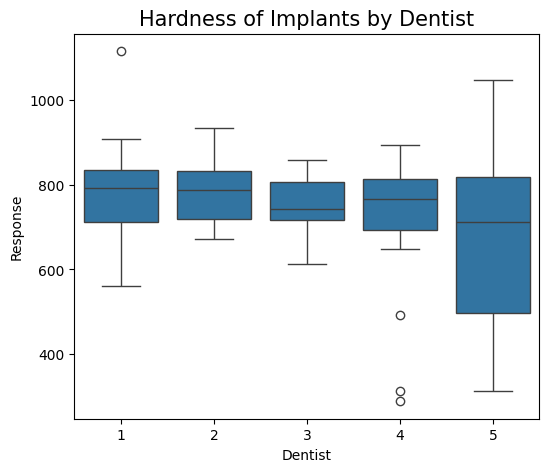

In [134]:
print(dental.groupby('Dentist')['Response'].mean())
fig, ax = plt.subplots(figsize=(6, 5))
a = sns.boxplot(x='Dentist', y='Response', data=dental)
a.set_title("Hardness of Implants by Dentist", fontsize=15)
ax.set_xlabel('Dentist')
ax.set_ylabel('Response')
plt.show()

## The hardness of dental implants depends mainly on the method used and on the dentist–method combination, not on the dentist alone. Methods 1 and 2 are the better choices, and Method 3 should be avoided, especially by Dentists 4 and 5.